<a href="https://colab.research.google.com/github/zogydinesh/ITA-0616/blob/main/program8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rows: 30
   YearsExperience   Salary
0              1.1  38669.0
1              1.3  37384.0
2              1.5  43204.0
3              2.0  52305.0
4              2.2  45409.0 

Train size: 24  Test size: 6 

Slope (m)     = 9046.50
Intercept (c) = 26785.68
Equation: Salary = 9046.50 x Experience + 26785.68

Test results:
  MAE  = 6083.52
  MSE  = 43486701.91
  RMSE = 6594.44
  R2   = 0.7711
Train R2 = 0.9844

Actual vs Predicted (test data):
   6.8 yrs   Actual =     97373   Predicted =     88302
   3.2 yrs   Actual =     59866   Predicted =     55734
   3.9 yrs   Actual =     60326   Predicted =     62067
   4.5 yrs   Actual =     59688   Predicted =     67495
   6.0 yrs   Actual =     75424   Predicted =     81065
   3.0 yrs   Actual =     62035   Predicted =     53925

Predicted salary for 6.5 years of experience: 85588


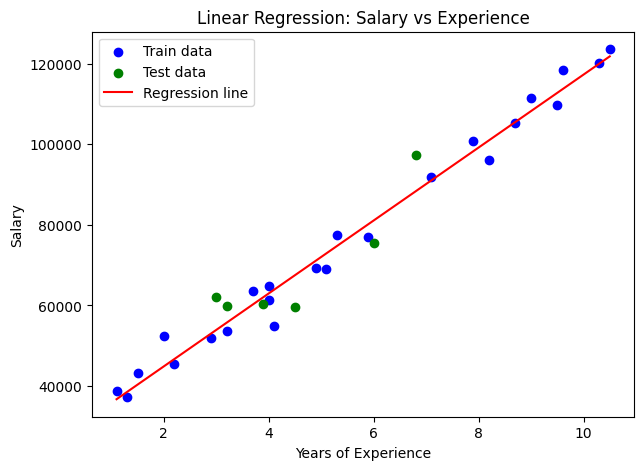

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset: Salary vs Years of Experience

# ---- 1. Load CSV (fallback to generating the dataset if missing) ----
try:
    df = pd.read_csv('Salary_Data.csv')
except (FileNotFoundError, Exception):
    # Generate the standard Salary_Data classic dataset
    np.random.seed(42)
    years = np.array([1.1, 1.3, 1.5, 2.0, 2.2, 2.9, 3.0, 3.2, 3.2, 3.7,
                      3.9, 4.0, 4.0, 4.1, 4.5, 4.9, 5.1, 5.3, 5.9, 6.0,
                      6.8, 7.1, 7.9, 8.2, 8.7, 9.0, 9.5, 9.6, 10.3, 10.5])

    # Approximate the classic salary mapping with a linear trend + random noise
    salaries = 25792 + 9449 * years + np.random.normal(0, 5000, len(years))

    df = pd.DataFrame({
        'YearsExperience': years,
        'Salary': salaries.round(0)
    })
    df.to_csv('Salary_Data.csv', index=False)

x = df['YearsExperience'].values.astype(float)
y = df['Salary'].values.astype(float)
print("Rows:", len(df))
print(df.head(), "\n")

# ---- 2. Train / test split (80% / 20%) ----
np.random.seed(42)
idx = np.random.permutation(len(x))
split = int(0.8 * len(x))
xtr, xte = x[idx[:split]], x[idx[split:]]
ytr, yte = y[idx[:split]], y[idx[split:]]
print("Train size:", len(xtr), " Test size:", len(xte), "\n")

# ---- 3. Train: least squares formula  y = m*x + c ----
m = np.sum((xtr - xtr.mean()) * (ytr - ytr.mean())) / np.sum((xtr - xtr.mean()) ** 2)
c = ytr.mean() - m * xtr.mean()
print(f"Slope (m)     = {m:.2f}")
print(f"Intercept (c) = {c:.2f}")
print(f"Equation: Salary = {m:.2f} x Experience + {c:.2f}\n")

# ---- 4. Predict ----
def predict(v):
    return m * v + c

pred_te = predict(xte)

# ---- 5. Evaluate ----
def metrics(actual, predicted):
    mse = np.mean((actual - predicted) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(actual - predicted))
    ss_res = np.sum((actual - predicted) ** 2)
    ss_tot = np.sum((actual - actual.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    return mse, rmse, mae, r2

mse, rmse, mae, r2 = metrics(yte, pred_te)
print("Test results:")
print(f"  MAE  = {mae:.2f}")
print(f"  MSE  = {mse:.2f}")
print(f"  RMSE = {rmse:.2f}")
print(f"  R2   = {r2:.4f}")
print(f"Train R2 = {metrics(ytr, predict(xtr))[3]:.4f}\n")

# ---- 6. Actual vs predicted ----
print("Actual vs Predicted (test data):")
for xv, a, p in zip(xte, yte, pred_te):
    print(f"  {xv:4.1f} yrs   Actual = {a:9.0f}   Predicted = {p:9.0f}")

# ---- 7. Predict for a new value ----
new_exp = 6.5
print(f"\nPredicted salary for {new_exp} years of experience: {predict(new_exp):.0f}")

# ---- 8. Plot ----
plt.figure(figsize=(7, 5))
plt.scatter(xtr, ytr, color='blue', label='Train data')
plt.scatter(xte, yte, color='green', label='Test data')
line = np.linspace(x.min(), x.max(), 100)
plt.plot(line, predict(line), color='red', label='Regression line')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Linear Regression: Salary vs Experience')
plt.legend()
plt.show()